# Прогнозирование оттока клиентов

Абельцев Герман Сергеевич, Д-Э 18-25. Курсовой проект по технологиям обработки больших данных.

## Результат

Лучший результат дал градиентный бустинг. На независимом тесте AP = 0,9003, ROC AUC = 0,9742. Порог 0,05 найден на валидации по F2. Он позволил найти 88 из 90 уходов при 61 ложной тревоге. Показатели характеризуют опубликованную выборку, а не будущую работу у другого оператора.

## Метод и условия

Исходник: [UCI Iranian Churn](https://archive.ics.uci.edu/dataset/563/iranian+churn+dataset), лицензия CC BY 4.0. Признаки охватывают первые 9 месяцев, метка — состояние к концу 12-го. Полные дубликаты удаляются; совпадающие профили не пересекаются между частями. Обучение, валидация и тест разделены приблизительно как 60/20/20.

Блокнот запускается из распакованного каталога проекта. Сначала установите зависимости: `python -m pip install -r requirements.txt`. Для Colab предварительно перенесите каталог с `src` и `data`; здесь не требуется авторизация в каких-либо сервисах. Повторный расчет записывается в `notebook_run`, исходные контрольные результаты остаются в `results`.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'src/churn.py').exists():
    raise RuntimeError('Откройте блокнот из каталога churn_project')
sys.path.insert(0, str(ROOT / 'src'))
from churn import load_data, split_data, train, FEATURES, predict_frame
plt.rcParams.update({'figure.figsize': (8, 4), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})

## Данные

Номер строки нужен для воспроизводимости, но не используется как признак. Исключены Status, Customer Value, Age и Age Group. Это ограничивает зависимость модели от спорной трактовки статуса и расчетной ценности.

In [2]:
data, audit = load_data(ROOT / 'data/customer_churn.csv')
pd.Series({k: audit[k] for k in ['raw_rows', 'clean_rows', 'exact_duplicates_removed', 'missing_values', 'clean_churn', 'unique_profiles', 'conflicting_profiles']}, name='Значение').to_frame()

,Значение
raw_rows,3150
clean_rows,2850
exact_duplicates_removed,300
missing_values,0
clean_churn,446
unique_profiles,2785
conflicting_profiles,18


In [3]:
splits = split_data(data)
pd.DataFrame([{'Часть': key, 'Строк': len(idx), 'Уходов': int(data.iloc[idx].Churn.sum()), 'Профилей': data.iloc[idx].profile_group.nunique()} for key, idx in splits.items()])

,Часть,Строк,Уходов,Профилей
0,train,1707,266,1664
1,validation,572,90,561
2,test,571,90,560


## Обучение и выбор

Семейство и параметры выбираются по средней AP трех групповых разбиений обучения. Порог выбирается по F2 на валидации. Все решения принимаются до итоговой оценки теста. Следующая ячейка действительно повторяет расчет, а не только читает готовую таблицу.

In [4]:
result = train(ROOT / 'notebook_run')
comparison = pd.DataFrame(result['model_comparison'])
comparison[['model', 'cv_ap', 'cv_std', 'validation_ap', 'fit_seconds']].round(4)

Обучение: dummy


Обучение: logistic


Обучение: forest


Обучение: boosting


{
  "winner": "boosting",
  "threshold": 0.05,
  "test": {
    "ap": 0.9002897492125482,
    "roc_auc": 0.9741741741741741,
    "precision": 0.5906040268456376,
    "recall": 0.9777777777777777,
    "f1": 0.7364016736401674,
    "f2": 0.8644400785854617,
    "accuracy": 0.8896672504378283,
    "brier": 0.045690772589529104,
    "confusion": [
      [
        420,
        61
      ],
      [
        2,
        88
      ]
    ]
  }
}


,model,cv_ap,cv_std,validation_ap,fit_seconds
0,dummy,0.1558,0.0006,0.1573,0.0785
1,logistic,0.7386,0.0215,0.7441,0.3868
2,forest,0.8823,0.0308,0.8499,5.6796
3,boosting,0.9116,0.0356,0.8786,1.0911


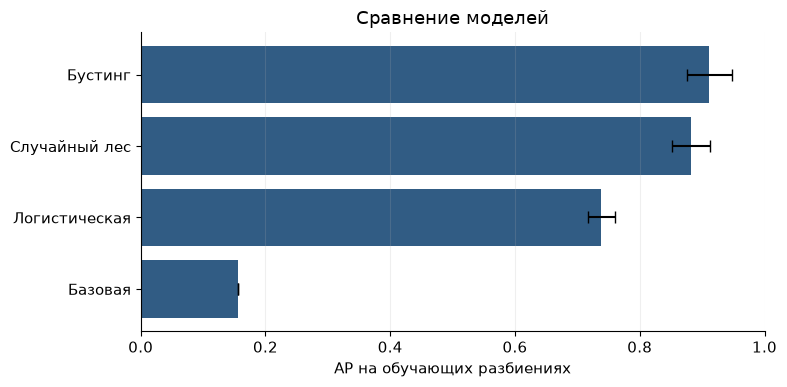

In [5]:
names = {'dummy': 'Базовая', 'logistic': 'Логистическая', 'forest': 'Случайный лес', 'boosting': 'Бустинг'}
fig, ax = plt.subplots()
ax.barh([names[n] for n in comparison.model], comparison.cv_ap, xerr=comparison.cv_std, color='#315C84', capsize=4)
ax.set(xlabel='AP на обучающих разбиениях', xlim=(0, 1), title='Сравнение моделей')
ax.grid(axis='x', alpha=.2)
plt.tight_layout()
plt.show()

Бустинг выбран по обучающим разбиениям. Полоски показывают стандартное отклонение трех значений AP, а не доверительные интервалы превосходства алгоритмов.

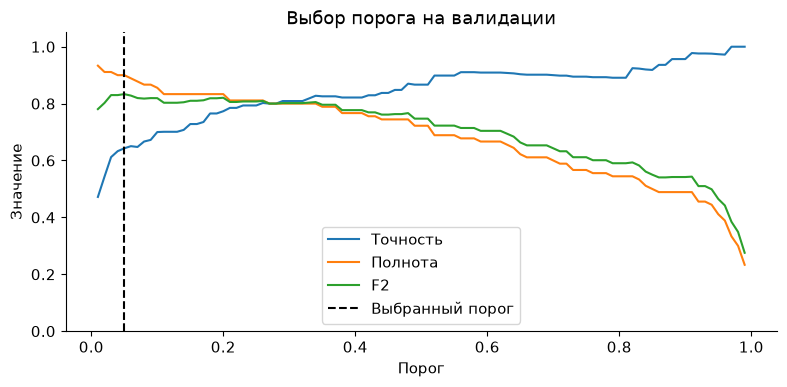

In [6]:
thresholds = pd.read_csv(ROOT / 'notebook_run/threshold_validation.csv')
fig, ax = plt.subplots()
for key, label in [('precision', 'Точность'), ('recall', 'Полнота'), ('f2', 'F2')]:
    ax.plot(thresholds.threshold, thresholds[key], label=label)
ax.axvline(result['threshold'], color='black', linestyle='--', label='Выбранный порог')
ax.set(xlabel='Порог', ylabel='Значение', ylim=(0, 1.05), title='Выбор порога на валидации')
ax.legend()
plt.tight_layout()
plt.show()

## Независимый тест

После выбора порога проверяется фиксированное решение. Сравнение с 0,5 показывает цену увеличения полноты, но не используется для пересмотра победителя по тестовым данным.

In [7]:
pd.DataFrame({label: {k: result[key][k] for k in ['ap', 'roc_auc', 'precision', 'recall', 'f1', 'f2', 'accuracy', 'brier']} for label, key in [('Базовая', 'dummy_test'), ('Порог 0.5', 'test_at_05'), ('Выбранный порог', 'test')]}).round(4)

,Базовая,Порог 0.5,Выбранный порог
ap,0.1576,0.9003,0.9003
roc_auc,0.5000,0.9742,0.9742
precision,0.0000,0.8228,0.5906
recall,0.0000,0.7222,0.9778
f1,0.0000,0.7692,0.7364
f2,0.0000,0.7403,0.8644
accuracy,0.8424,0.9317,0.8897
brier,0.1328,0.0457,0.0457


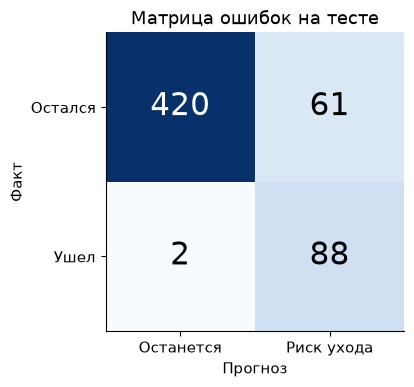

In [8]:
cm = np.array(result['test']['confusion'])
fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=22, color='white' if cm[i,j] > 220 else 'black')
ax.set(xticks=[0,1], yticks=[0,1], xticklabels=['Останется','Риск ухода'], yticklabels=['Остался','Ушел'], xlabel='Прогноз', ylabel='Факт', title='Матрица ошибок на тесте')
plt.tight_layout()
plt.show()

Модель нашла 88 уходов и пропустила 2. Из 149 клиентов в группе риска 61 не ушел. Высокая полнота здесь сопровождается дополнительной нагрузкой на службу поддержки.

In [9]:
pd.DataFrame(result['bootstrap_95'], index=['Нижняя граница', 'Верхняя граница']).T.round(4)

,Нижняя граница,Верхняя граница
ap,0.8476,0.9407
roc_auc,0.9575,0.9864
recall,0.9437,1.0000
precision,0.5155,0.6644
f1,0.6731,0.7919


Интервалы получены bootstrap-перевыборкой профилей. Они относятся к фиксированной модели и не учитывают изменение компании или будущего периода.

## Применение модели

Показывается тот же конвейер, который используется в командном пакетном прогнозировании.

In [10]:
import joblib
bundle = joblib.load(ROOT / 'notebook_run/model.joblib')
example = pd.read_csv(ROOT / 'data/example_customers.csv')
predict_frame(bundle, example).round(6)

,probability,risk_flag
0,0.001818,0
1,0.000590,0
2,0.000398,0
3,0.000835,0
4,0.998724,1
5,0.535255,1
6,0.000254,0
7,0.001467,0
8,0.002354,0
9,0.276848,1


## Нагрузочный эксперимент

Ниже — сохраненные медианы трех запусков для каждой комбинации. Для повторного измерения выполните `python benchmark.py`. Файлы до 500 000 строк сформированы повторением исходных профилей. Они измеряют ресурсы программы и не используются в обучении или проверке качества.

In [11]:
load = pd.read_csv(ROOT / 'results/load_summary.csv')
load.round(3)

,rows,batch,seconds,rows_per_second,peak_rss_mib,delta_rss_mib
0,10000,5000,0.115,86804.049,176.953,10.125
1,10000,25000,0.109,91717.371,178.055,11.004
2,100000,5000,0.728,137379.074,178.582,11.762
3,100000,25000,0.559,178872.893,194.953,28.293
4,500000,5000,3.372,148301.120,179.992,13.141
5,500000,25000,2.676,186821.527,196.609,30.207


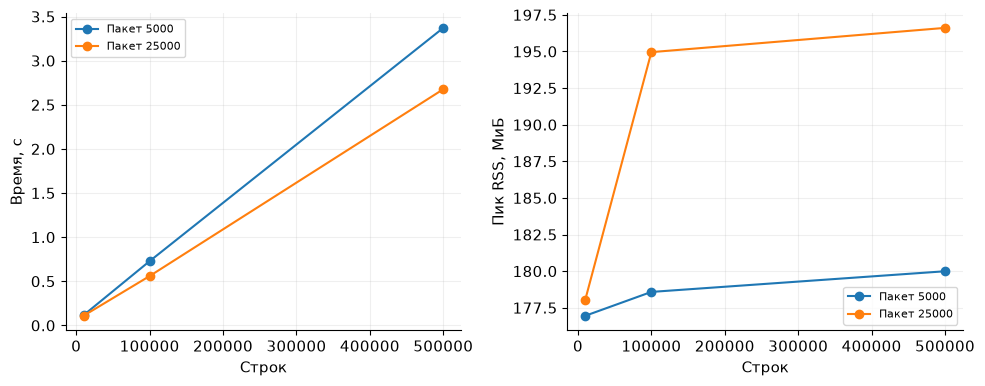

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for batch, part in load.groupby('batch'):
    axes[0].plot(part.rows, part.seconds, marker='o', label=f'Пакет {batch}')
    axes[1].plot(part.rows, part.peak_rss_mib, marker='o', label=f'Пакет {batch}')
axes[0].set(xlabel='Строк', ylabel='Время, с')
axes[1].set(xlabel='Строк', ylabel='Пик RSS, МиБ')
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=.2)
    ax.ticklabel_format(style='plain', axis='x')
plt.tight_layout()
plt.show()

## Контроль воспроизведения

Сравниваются метрики повторного обучения и сохраненного контрольного запуска. Время обучения не сравнивается: оно зависит от нагрузки компьютера.

In [13]:
reference = json.loads((ROOT / 'results/metrics.json').read_text(encoding='utf-8'))
assert result['winner'] == reference['winner']
assert result['threshold'] == reference['threshold']
for key in ['ap', 'roc_auc', 'precision', 'recall', 'f1', 'f2']:
    np.testing.assert_allclose(result['test'][key], reference['test'][key], rtol=1e-9, atol=1e-12)
print('Контрольные метрики совпали. Повторный запуск завершен.')

Контрольные метрики совпали. Повторный запуск завершен.


## Выводы

На данном наборе нелинейные модели дали более высокую AP. Бустинг и порог, выбранный по F2, обеспечили высокое покрытие уходящих клиентов с заметным числом ложных тревог. Пакетное чтение ограничивает потребление памяти при увеличении файла. Перед практическим внедрением нужны данные за более поздний период, проверка у конкретной компании и оценка реального эффекта удержания. Без эксперимента с клиентами технические метрики нельзя переводить в обещанную прибыль.